# Alternative use 3: statistical analysis of Beacon's public API in a notebook

**API accessed:** `GET https://simonhwang1998.pythonanywhere.com/api/skills/summary/` (public, no login, JSON).
**Data used:** one row per skill with `learners`, `avg_proficiency`, `avg_required`, `avg_gap`, `tasks`.
**Result:** descriptive statistics, a correlation test, and a check of whether Beacon's preparation tasks are aimed at the skills with the widest gaps.

Who would use this: a data-minded advisor or researcher asking *"is the coaching content pointed at the right skills?"*, a question the website itself never answers.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

API = "https://simonhwang1998.pythonanywhere.com/api/skills/summary/"
df = pd.read_json(API)          # the API returns a flat JSON array, so this is one line
print(f"{len(df)} skills loaded from {API}")
df.head()

12 skills loaded from https://simonhwang1998.pythonanywhere.com/api/skills/summary/


,skill,category,learners,avg_proficiency,avg_required,avg_gap,tasks
0,Data structures & algorithms,Technical,3,43.3,70.0,26.7,2
1,Financial markets basics,Domain knowledge,4,50.5,65.0,14.5,1
2,Handling failure questions,Behavioral,2,48.0,72.5,24.5,0
3,Negotiating an offer,Behavioral,3,59.3,73.3,14.0,4
4,Product sense,Domain knowledge,4,61.2,78.8,17.6,0


## 1. Descriptive statistics (assessed skills only)

In [2]:
assessed = df[df["learners"] > 0].copy()
assessed[["learners", "avg_proficiency", "avg_required", "avg_gap", "tasks"]].describe().round(1)

,learners,avg_proficiency,avg_required,avg_gap,tasks
count,10.0,10.0,10.0,10.0,10.0
mean,2.4,50.3,71.0,20.6,2.1
std,1.1,9.6,7.8,8.8,1.7
min,1.0,33.0,60.0,6.5,0.0
25%,2.0,46.5,66.2,14.1,0.2
50%,2.0,48.5,72.5,21.0,2.5
75%,3.0,57.1,73.1,26.5,3.8
max,4.0,66.0,85.0,36.0,4.0


## 2. Do harder requirements go with lower proficiency?
Pearson correlation between what roles require and what candidates score.

In [3]:
r = assessed["avg_required"].corr(assessed["avg_proficiency"])
r_gap_tasks = assessed["avg_gap"].corr(assessed["tasks"])
print(f"required vs proficiency: r = {r:+.2f}")
print(f"gap vs number of preparation tasks: r = {r_gap_tasks:+.2f}")

required vs proficiency: r = +0.50
gap vs number of preparation tasks: r = -0.10


## 3. Are preparation tasks aimed at the biggest gaps?
A skill is *under-served* if its gap is above the median but it has fewer tasks than the median.

In [4]:
gap_median, task_median = assessed["avg_gap"].median(), assessed["tasks"].median()
assessed["status"] = "ok"
assessed.loc[(assessed.avg_gap > gap_median) & (assessed.tasks < task_median), "status"] = "UNDER-SERVED"
assessed.loc[(assessed.avg_gap < gap_median) & (assessed.tasks > task_median), "status"] = "over-served"
assessed.sort_values("avg_gap", ascending=False)[["skill", "category", "avg_gap", "tasks", "status"]]

,skill,category,avg_gap,tasks,status
7,SQL & relational modeling,Technical,36.0,4,ok
10,Version control with Git,Technical,27.0,0,UNDER-SERVED
0,Data structures & algorithms,Technical,26.7,2,UNDER-SERVED
9,System design basics,Technical,26.0,3,ok
2,Handling failure questions,Behavioral,24.5,0,UNDER-SERVED
4,Product sense,Domain knowledge,17.6,0,ok
1,Financial markets basics,Domain knowledge,14.5,1,ok
3,Negotiating an offer,Behavioral,14.0,4,over-served
11,Whiteboard communication,Communication,13.5,4,over-served
6,Resume & elevator pitch,Communication,6.5,3,over-served


## 4. Chart: gap against coaching effort

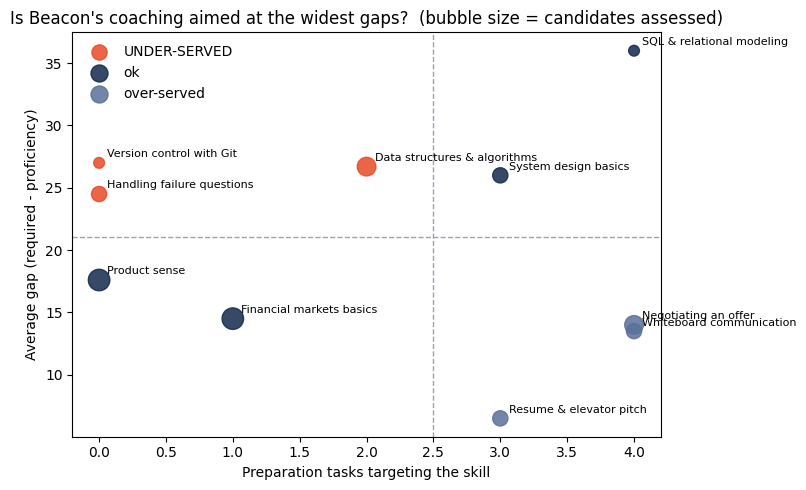

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
colours = {"UNDER-SERVED": "#e84a27", "over-served": "#5a7099", "ok": "#13294b"}
for status, group in assessed.groupby("status"):
    ax.scatter(group["tasks"], group["avg_gap"], s=group["learners"] * 60,
               color=colours[status], alpha=0.85, label=status)
for _, row in assessed.iterrows():
    ax.annotate(row["skill"], (row["tasks"], row["avg_gap"]), fontsize=8,
                xytext=(6, 4), textcoords="offset points")
ax.axhline(gap_median, color="#9aa3b2", linestyle="--", linewidth=1)
ax.axvline(task_median, color="#9aa3b2", linestyle="--", linewidth=1)
ax.set_xlabel("Preparation tasks targeting the skill")
ax.set_ylabel("Average gap (required - proficiency)")
ax.set_title("Is Beacon's coaching aimed at the widest gaps?  (bubble size = candidates assessed)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 5. Finding

In [6]:
under = assessed[assessed.status == "UNDER-SERVED"].sort_values("avg_gap", ascending=False)
print(f"{len(under)} skill(s) have an above-median gap but below-median task coverage:")
for _, row in under.iterrows():
    print(f"  - {row.skill}: gap {row.avg_gap:.1f} points, only {row.tasks} task(s)")

3 skill(s) have an above-median gap but below-median task coverage:
  - Version control with Git: gap 27.0 points, only 0 task(s)
  - Data structures & algorithms: gap 26.7 points, only 2 task(s)
  - Handling failure questions: gap 24.5 points, only 0 task(s)
